# GRU Round 4 — learning-rate tuning
Compare **0.0003, 0.001 and 0.003** using the hidden size selected by completed Round 3. Only learning rate changes. Carry forward the class-weight exponent, head dropout, weight decay, batch size, seed, folds and early-stopping policy. Every fold starts with fresh model weights; this is **3 configurations × 5 folds = 15 fits** before resuming completed Round 4 folds.

**Before running:** finish Round 3, then set `ROUND3_RUN_DIR` below to its printed output directory. Keep Round 1/2/3 output directories and cleaned input files available at their original paths. The notebook verifies the upstream chain, selects the Round 3 winner using mean fold trapezoidal PR AUC (ROC AUC then smaller hidden size break ties), and copies its settings automatically. There is no need to type the winning hidden size or class weight.

**Training policy:** inherited from Round 3 (normally maximum 50 epochs, patience 5, minimum improvement 0.001). Independently restore the checkpoint with the highest observed validation trapezoidal PR AUC. The selected positive weight is recalculated from each fold's training labels. Round 3 checkpoints are not loaded into Round 4 models. The reference learning rate is rerun here to keep all three results under this run's software and device.

**Evaluation:** reuse original saved TRAIN folds and all split checks, including the previously confirmed dataset2 shared-position interpretation. TEST identifiers are audited, but TEST labels and predictions are excluded from tuning. Final TEST evaluation belongs after the remaining tuning stages. This round does not refit on all TRAIN.

**Validation status:** notebook format and Python syntax checked. Synthetic checks passed for configuration carry-forward, learning-rate-only changes, stopping logic, summary export and all plot cells. A synthetic three-candidate epoch figure was visually inspected. Actual PyTorch training and checkpoint/resume execution remain untested here because PyTorch and your run artifacts are unavailable. Full real-data execution requires your cleaned CSVs and completed Round 1/2/3 outputs on Ronin; no experimental results are embedded. Select the `m6a-gru` kernel, then Restart Kernel → Run All.


## 1. Environment

In [1]:
# Uncomment once if packages are missing; restart the kernel afterwards.
# %pip install "numpy>=1.24,<3" "pandas>=2,<3" "scikit-learn>=1.3,<2" "matplotlib>=3.7,<4" "torch>=2.2,<3" "joblib>=1.3,<2" ipykernel
from pathlib import Path
from datetime import datetime, timezone
import gc, gzip, hashlib, importlib.metadata, json, random, re, shutil, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import StratifiedGroupKFold, ParameterSampler
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
    roc_curve, auc, precision_score, recall_score, f1_score, accuracy_score)
from IPython.display import display
plt.rcParams.update({'figure.figsize': (8, 4), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 20)
import time

## 2. Paths and controls
Set `ROUND3_RUN_DIR` to the completed Round 3 run. Keep outputs excluded from Git. New results go under `/output/gru_learning_rate_round4` by default; change `OUTPUT_ROOT` if needed.

Use `EXISTING_RUN_DIR` to resume this round. Completed compatible folds reload; interrupted folds restart. Set `RUN_TRAINING=False` with a completed Round 4 directory to regenerate tables and plots. Keep upstream directories available in either mode.

CPU/CUDA selection remains automatic. Only learning rate varies; the epoch policy is inherited rather than re-tuned here.

In [8]:
PROJECT_ROOT = Path('/home/ubuntu/project')
ROUND3_RUN_DIR = PROJECT_ROOT / 'outputs' / 'gru_early_stopping_round3' / '20261014T094624_736944Z'
OUTPUT_ROOT = PROJECT_ROOT / 'outputs' / 'gru_learning_rate_round4'  # EDIT if your writable output folder differs
RUN_TRAINING = True
EXISTING_RUN_DIR = None  # Set to an existing Round 4 directory to resume or reload.
LEARNING_RATES = [3e-4, 1e-3, 3e-3]
THRESHOLD = 0.5
PREDICT_BATCH_SIZE = 1024
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def resolve_path(value):
    p = Path(value).expanduser()
    return (p if p.is_absolute() else PROJECT_ROOT / p).resolve()
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

if not RUN_TRAINING:
    if EXISTING_RUN_DIR is None: raise ValueError('Set EXISTING_RUN_DIR to a completed Round 4 run.')
    previous = json.loads((resolve_path(EXISTING_RUN_DIR)/'run_manifest.json').read_text())
    ROUND3_RUN_DIR = Path(previous['round3_run_dir'])
ROUND3_RUN_DIR = resolve_path(ROUND3_RUN_DIR)
round3_manifest = json.loads((ROUND3_RUN_DIR/'run_manifest.json').read_text())
round3_board = pd.read_csv(ROUND3_RUN_DIR/'leaderboard.csv')
if round3_manifest['contract']['stage'] != 'early_stopping_round3_v1':
    raise ValueError('Expected the supplied Round 3 early-stopping experiment.')
if len(round3_board) != 2 or set(round3_board.hidden_size) != {32,64}:
    raise ValueError('Finish both Round 3 candidates before running Round 4.')
if not np.isfinite(round3_board[['mean_PR_AUC','mean_ROC_AUC']]).all().all():
    raise ValueError('Invalid Round 3 metrics.')
round3_selected = round3_board.sort_values(
    ['mean_PR_AUC','mean_ROC_AUC','hidden_size'], ascending=[False,False,True]).iloc[0]
ROUND3_CONFIG = json.loads((ROUND3_RUN_DIR/str(round3_selected.candidate)/'config.json').read_text())
# Require all five completed folds for both source candidates.
for candidate in round3_board.candidate:
    for k in range(1, int(round3_manifest['contract']['n_folds'])+1):
        marker = ROUND3_RUN_DIR/candidate/f'fold_{k}_complete.json'
        record = json.loads(marker.read_text())
        if record['signature'] != round3_manifest['signature']:
            raise ValueError('Round 3 contains incompatible fold results.')
ROUND2_RUN_DIR = resolve_path(round3_manifest['round2_run_dir'])
round2_manifest = json.loads((ROUND2_RUN_DIR/'run_manifest.json').read_text())
round2_board = pd.read_csv(ROUND2_RUN_DIR/'leaderboard.csv')
if round2_manifest['contract']['stage'] != 'hidden_size_fixed_epochs_v1':
    raise ValueError('Expected the supplied Round 2 fixed-epoch experiment.')
if len(round2_board) != 2 or set(round2_board.hidden_size) != {32, 64}:
    raise ValueError('Finish both Round 2 candidates first.')
if not np.isfinite(round2_board[['mean_PR_AUC', 'mean_ROC_AUC']]).all().all():
    raise ValueError('Invalid Round 2 metrics.')
ROUND1_RUN_DIR = resolve_path(round2_manifest['round1_run_dir'])
source_manifest = json.loads((ROUND1_RUN_DIR/'run_manifest.json').read_text())
source_leaderboard = pd.read_csv(ROUND1_RUN_DIR/'leaderboard.csv')
if len(source_leaderboard) != len(source_manifest['alphas']):
    raise ValueError('Round 1 must finish all candidates before selecting alpha.')
if not np.allclose(sorted(source_leaderboard.alpha), sorted(source_manifest['alphas'])):
    raise ValueError('Round 1 alpha candidates do not match its manifest.')
if not np.isfinite(source_leaderboard[['mean_PR_AUC','mean_ROC_AUC']]).all().all():
    raise ValueError('Invalid Round 1 selection metrics.')
source_selected = source_leaderboard.sort_values(
    ['mean_PR_AUC','mean_ROC_AUC','alpha'], ascending=[False,False,True]).iloc[0]
SELECTED_ALPHA = float(source_selected.alpha)
SOURCE_CANDIDATE = str(source_selected.candidate)
BASE_CONFIG = source_manifest['base_config'].copy()
expected = dict(hidden_size=32, dropout=0.2, lr=1e-3, weight_decay=1e-4,
                batch_size=256, epochs=20, class_weighting=True)
if BASE_CONFIG != expected:
    raise ValueError('Round 1 fixed settings differ from the inspected notebook; review before running.')
SEED = int(source_manifest['seed']); N_FOLDS = int(source_manifest['n_folds'])
if N_FOLDS != 5: raise ValueError('This experiment requires the five Round 1 folds.')
source_audit = json.loads((ROUND1_RUN_DIR/'split_audit.json').read_text())
DATASET2_POSITION_GROUPS_CONFIRMED = bool(source_audit['dataset2_position_groups_confirmed'])
DATASETS = [dict(dataset_id=name, **{k:paths[k] for k in ['train_file','test_file','manifest_file']})
            for name,paths in source_manifest['inputs'].items()]
if (round2_manifest['contract']['alpha'] != SELECTED_ALPHA
        or round2_manifest['contract']['base_config'] != BASE_CONFIG
        or round2_manifest['contract']['seed'] != SEED
        or round2_manifest['contract']['n_folds'] != N_FOLDS):
    raise ValueError('Round 1 and Round 2 settings disagree.')
r3 = round3_manifest['contract']
if any(r3[key] != value for key,value in dict(base_config=BASE_CONFIG,alpha=SELECTED_ALPHA,seed=SEED,n_folds=N_FOLDS).items()):
    raise ValueError('Round 3 disagrees with upstream settings.')
MAX_EPOCHS, PATIENCE, MIN_DELTA = int(r3['max_epochs']), int(r3['patience']), float(r3['min_delta'])
expected_round3 = dict(BASE_CONFIG, hidden_size=int(round3_selected.hidden_size), alpha=SELECTED_ALPHA,
                      epochs=MAX_EPOCHS, patience=PATIENCE, min_delta=MIN_DELTA)
if ROUND3_CONFIG != expected_round3:
    raise ValueError('Round 3 winning config differs from its recorded experiment.')
BASE_CONFIG = ROUND3_CONFIG.copy()
REFERENCE_LR = float(BASE_CONFIG['lr'])
LEARNING_RATES = sorted(set([float(x) for x in LEARNING_RATES] + [REFERENCE_LR]))
if not all(np.isfinite(x) and x > 0 for x in LEARNING_RATES):
    raise ValueError('Learning rates must be finite and positive.')
if not RUN_TRAINING:
    if previous['contract']['stage'] != 'learning_rate_round4_v1':
        raise ValueError('EXISTING_RUN_DIR must be a Round 4 run.')
    LEARNING_RATES = previous['contract']['learning_rates']
if MAX_EPOCHS < 1 or PATIENCE < 1 or MIN_DELTA < 0:
    raise ValueError('Invalid early-stopping settings.')
seed_everything(SEED)
print('Device:', DEVICE, '| Selected alpha:', SELECTED_ALPHA)
print('Positive weight per fit: (training negatives / training positives) ** alpha')
print('Inherited Round 3 configuration:', BASE_CONFIG)
print('Learning rates:', LEARNING_RATES)
print('New fits before resume:', N_FOLDS * len(LEARNING_RATES))

Device: cpu | Selected alpha: 0.0
Positive weight per fit: (training negatives / training positives) ** alpha
Inherited Round 3 configuration: {'hidden_size': 32, 'dropout': 0.2, 'lr': 0.001, 'weight_decay': 0.0001, 'batch_size': 256, 'epochs': 50, 'class_weighting': True, 'alpha': 0.0, 'patience': 5, 'min_delta': 0.001}
Learning rates: [0.0003, 0.001, 0.003]
New fits before resume: 15


## 3. Load and validate the unchanged cleaned features
Scaling is still fitted only within training folds. Results-only mode skips input loading.

In [9]:
LOCATIONS = ['minus1', 'center', 'plus1']
MEASURES = ['dwell', 'signal_sd', 'signal_mean']
STATS = ['mean', 'std', 'median', 'q25', 'q75']
# Explicit ordering is essential: do not reshape the CSV's original column order.
POSITION_COLUMNS = [[f'{loc}_{measure}_{stat}' for stat in STATS for measure in MEASURES]
                    for loc in LOCATIONS]
SUMMARY_COLUMNS = [c for cols in POSITION_COLUMNS for c in cols]
KEY = ['transcript_id', 'transcript_position']

def validate_features(frame):
    required = KEY + ['sequence', 'n_reads_valid'] + SUMMARY_COLUMNS
    missing = sorted(set(required) - set(frame.columns))
    if missing: raise ValueError(f'Missing feature columns: {missing}')
    if frame.empty: raise ValueError('No sites found.')
    if frame[KEY].isna().any().any() or frame.duplicated(KEY).any():
        raise ValueError('Missing or duplicate site keys.')
    if frame.transcript_id.astype(str).str.strip().eq('').any():
        raise ValueError('Empty transcript ID.')
    pos = pd.to_numeric(frame.transcript_position, errors='raise').to_numpy(dtype=float)
    if not np.isfinite(pos).all() or (pos < 0).any() or (pos != np.floor(pos)).any():
        raise ValueError('Positions must be nonnegative integers.')
    seq = frame.sequence.astype('string')
    if not seq.str.fullmatch('[ACGT]{7}').fillna(False).all():
        raise ValueError('Expected seven-base A/C/G/T sequences.')
    if not seq.str.slice(1, 6).str.fullmatch('[AGT][AG]AC[ACT]').fillna(False).all():
        raise ValueError('Non-DRACH central motif; inspect cleaning.')
    values = frame[SUMMARY_COLUMNS + ['n_reads_valid']].to_numpy(dtype=float)
    if not np.isfinite(values).all() or (frame.n_reads_valid < 1).any():
        raise ValueError('Nonfinite summaries or invalid coverage.')

In [10]:
import warnings

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(1024*1024), b''): h.update(block)
    return h.hexdigest()

def read_partition(path, name, partition):
    frame = pd.read_csv(path, dtype={'transcript_id':str, 'gene_id':str, 'group_id':str})
    validate_features(frame)
    required = ['dataset_id','label','split','group_id','group_source','gene_id']
    if not set(required).issubset(frame): raise ValueError(f'{path}: missing split metadata')
    if not frame.dataset_id.eq(name).all() or not frame.split.eq(partition).all():
        raise ValueError(f'{path}: dataset or split mismatch')
    if not frame.label.isin([0,1]).all(): raise ValueError(f'{path}: binary labels required')
    if frame.group_id.isna().any() or frame.group_id.str.strip().eq('').any():
        raise ValueError(f'{path}: missing group_id')
    frame['label'] = frame.label.astype('int64')
    frame['transcript_position'] = frame.transcript_position.astype('int64')
    return frame.reset_index(drop=True)

if RUN_TRAINING:
    if N_FOLDS < 2 or PREDICT_BATCH_SIZE < 1: raise ValueError('Invalid settings')
    if len({c['dataset_id'] for c in DATASETS}) != len(DATASETS): raise ValueError('Duplicate dataset IDs')
    RUN_DIR = (resolve_path(EXISTING_RUN_DIR) if EXISTING_RUN_DIR is not None else
               OUTPUT_ROOT / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ'))
    RUN_DIR.mkdir(parents=True, exist_ok=True)
    train_tables, test_keys, input_paths, cleaning_manifests, summary = {}, [], {}, {}, []
    for c in DATASETS:
        name=c['dataset_id']
        paths={k:str(resolve_path(c[k])) for k in ['train_file','test_file','manifest_file']}
        meta=json.loads(Path(paths['manifest_file']).read_text())
        if meta.get('dataset_id') != name or meta.get('max_lines', 'missing') is not None:
            raise ValueError(f'{name}: require complete matching cleaner manifest')
        train=read_partition(paths['train_file'],name,'train')
        # Inspect TEST identifiers only for separation; labels/features are not used during tuning.
        keys=pd.read_csv(paths['test_file'],usecols=['dataset_id','transcript_id','transcript_position','gene_id','group_id','group_source','sequence','split'],
                         dtype={'transcript_id':str,'gene_id':str,'group_id':str})
        if keys.empty or not keys.split.eq('test').all() or not keys.dataset_id.eq(name).all():
            raise ValueError(f'{name}: invalid TEST metadata')
        if keys.group_id.isna().any() or keys.duplicated(KEY).any(): raise ValueError('Invalid TEST keys/groups')
        train_tables[name]=train; test_keys.append(keys)
        paths['train_sha256']=sha256_file(paths['train_file'])
        paths['test_sha256']=sha256_file(paths['test_file'])
        for key in ['train_sha256','test_sha256']:
            if paths[key] != source_manifest['inputs'][name][key]:
                raise ValueError(f'{name}: {key} differs from Round 1. Do not compare different inputs.')
        input_paths[name]=paths; cleaning_manifests[name]=meta
        summary.append(dict(dataset_id=name,train_sites=len(train),test_sites=len(keys),train_positive_fraction=train.label.mean()))
    train_df=pd.concat(train_tables.values(),ignore_index=True)
    test_key_df=pd.concat(test_keys,ignore_index=True)
    pd.DataFrame(summary).to_csv(RUN_DIR/'input_summary.csv',index=False)
    display(pd.DataFrame(summary))
else:
    if EXISTING_RUN_DIR is None: raise ValueError('Set EXISTING_RUN_DIR')
    RUN_DIR=resolve_path(EXISTING_RUN_DIR)
    if not (RUN_DIR/'leaderboard.csv').is_file(): raise FileNotFoundError('Completed run required')
    saved_manifest=json.loads((RUN_DIR/'run_manifest.json').read_text())
    input_paths=saved_manifest['inputs']
print('Outputs:',RUN_DIR)

,dataset_id,train_sites,test_sites,train_positive_fraction
0,dataset0,97879,23959,0.044933
1,dataset1,73380,17430,0.072758
2,dataset2,1015,308,0.857143


Outputs: /home/ubuntu/project/outputs/gru_learning_rate_round4/20261014T101021_587017Z


## 4. Audit train/test separation, then reuse saved training-only CV folds

**Datasets0 and 1:** link transcript, known gene and supplied group IDs into connected components. Keep these components disjoint across train/test and CV folds. Unknown gene annotations limit gene-disjoint claims.

**Dataset2:** strict transcript grouping is the default. Set `DATASET2_POSITION_GROUPS_CONFIRMED=True` only after checking the dataset's provenance confirms that `tx_id_0` through `tx_id_6` are mixture versions of a shared reference and the same position refers to the same underlying site. This notebook cannot establish that fact from the names, fractions or audit alone. With that explicit assumption, use the existing `dataset2:mixture_position:<position>` group for both held-out checks and CV. Repeated mixture IDs are then permitted. All rows at a shared position must remain together. This estimates generalization to held-out positions within this mixture construction, not unseen biological transcripts.

The enabled exception validates IDs, group-to-position correspondence, absence of gene annotations and sequence consistency within each position group. These are consistency checks, not proof of biological independence. Exact-site overlap checks remain enabled for every dataset. No rows, labels or supplied splits are changed. Annotation keys from test data are used only for split auditing/group consistency, never fitting.

If the position interpretation is false, obtain the true biological mapping and fix the shared split upstream for every team model. If it remains unknown, leave the option False; alternatively omit dataset2 from `DATASETS` for an explicitly dataset0/1-only experiment.

The dataset2 option is enabled here per your instruction that position-based splitting is appropriate. This assumption is recorded in split_audit.json. TEST identifiers and sequences are inspected only for split consistency, never to fit or select the model.


Round 4 loads Round 1 fold numbers by dataset and site identifier, validates labels and group separation, and saves the reused assignments.

In [11]:
if RUN_TRAINING:
    train_df['partition'] = 'train'
    test_df = test_key_df.copy()
    test_df['partition'] = 'test'
    # Union-find uses identifiers only; labels are never involved.
    all_keys = pd.concat([train_df, test_df], ignore_index=True)
    mixture_mask = (all_keys.dataset_id.eq('dataset2') & DATASET2_POSITION_GROUPS_CONFIRMED)
    if mixture_mask.any():
        mixture = all_keys.loc[mixture_mask]
        required = ['group_id', 'group_source', 'sequence']
        if any(c not in mixture for c in required):
            raise ValueError('Dataset2 position grouping requires group_id, group_source and sequence.')
        expected = 'dataset2:mixture_position:' + mixture.transcript_position.astype(str)
        if not mixture.group_id.astype('string').eq(expected).fillna(False).all():
            raise ValueError('Dataset2 group_id must match dataset2:mixture_position:<position>. Fix upstream metadata.')
        if not mixture.transcript_id.str.fullmatch(r'tx_id_[0-6]').all():
            raise ValueError('Unexpected dataset2 identifiers; review the position-group assumption.')
        if mixture.gene_id.notna().any():
            raise ValueError('Dataset2 has gene annotations; review these before using the mixture exception.')
        if mixture.groupby('group_id').sequence.nunique().gt(1).any():
            raise ValueError('Dataset2 sequences disagree within position groups. Review upstream mapping.')
        print('Dataset2: using explicitly confirmed shared-position groups, not mixture IDs.')
    else:
        print('Strict transcript/gene grouping. Dataset2 position exception has not been confirmed.')
    parent = {}
    def root(x):
        parent.setdefault(x, x)
        while parent[x] != x:
            parent[x] = parent[parent[x]]; x = parent[x]
        return x
    def link(a, b):
        ra, rb = root(a), root(b)
        if ra != rb: parent[rb] = ra
    known_pairs = []
    row_nodes = []
    for row in all_keys.itertuples(index=False):
        if DATASET2_POSITION_GROUPS_CONFIRMED and row.dataset_id == 'dataset2':
            node = 'mixture:' + str(row.group_id)
            root(node)
            row_nodes.append(node)
            continue
        tx = 'transcript:' + row.transcript_id
        row_nodes.append(tx)
        root(tx)
        gene = row.gene_id
        supplied = getattr(row, 'group_id', pd.NA)
        if pd.notna(supplied) and str(supplied).startswith('gene:'):
            group_gene = str(supplied)[5:]
            if pd.notna(gene) and str(gene) != group_gene:
                raise ValueError('gene_id conflicts with gene-based group_id.')
            gene = group_gene
        if pd.notna(gene):
            known_pairs.append((row.transcript_id, str(gene)))
            link(tx, 'gene:' + str(gene))
        if pd.notna(supplied): link(tx, 'supplied:' + str(supplied))
    known = pd.DataFrame(known_pairs, columns=['transcript_id','gene_id']).drop_duplicates()
    if known.groupby('transcript_id').gene_id.nunique().gt(1).any():
        raise ValueError('Conflicting transcript-to-gene annotations.')
    components = pd.Series([root(node) for node in row_nodes], index=all_keys.index)
    groups = components.iloc[:len(train_df)].reset_index(drop=True)
    test_groups = components.iloc[len(train_df):].reset_index(drop=True)
    shared_groups = set(groups) & set(test_groups)
    shared_sites = train_df[KEY].drop_duplicates().merge(test_df[KEY].drop_duplicates(), on=KEY)
    strict_train = all_keys.loc[~mixture_mask & all_keys.partition.eq('train')]
    strict_test = all_keys.loc[~mixture_mask & all_keys.partition.eq('test')]
    shared_transcripts = set(strict_train.transcript_id) & set(strict_test.transcript_id)
    mixture_train = all_keys.loc[mixture_mask & all_keys.partition.eq('train')]
    mixture_test = all_keys.loc[mixture_mask & all_keys.partition.eq('test')]
    allowed_mixture_ids = set(mixture_train.transcript_id) & set(mixture_test.transcript_id)
    audit = dict(shared_sites=len(shared_sites), shared_transcripts=len(shared_transcripts),
                 shared_biological_groups=len(shared_groups),
                 dataset2_position_groups_confirmed=DATASET2_POSITION_GROUPS_CONFIRMED,
                 allowed_shared_mixture_ids=sorted(allowed_mixture_ids), train_rows=len(train_df), test_rows=len(test_df))
    (RUN_DIR/'split_audit.json').write_text(json.dumps(audit, indent=2))
    all_keys[['dataset_id','partition']+KEY+['gene_id']].assign(cv_group=components).to_csv(
        RUN_DIR/'input_split_assignments.csv.gz', index=False)
    if shared_groups or len(shared_sites) or shared_transcripts:
        all_keys.loc[components.isin(shared_groups), ['dataset_id','partition']+KEY+['gene_id']].to_csv(
            RUN_DIR/'train_test_overlap.csv', index=False)
        raise ValueError(f'Train/test biological overlap: {audit}. See train_test_overlap.csv. '
                         'For dataset2 mixture IDs, first confirm the shared-position interpretation '
                         'and then set DATASET2_POSITION_GROUPS_CONFIRMED=True in Section 2. '
                         'Otherwise repair the upstream shared split consistently for all models.')
    print('Train/test separation passed:', audit)
    if groups.nunique() < N_FOLDS: raise ValueError('Too few independent groups for configured folds.')
    grouping_summary = dict(known_gene_rows=int(train_df.gene_id.notna().sum()),
                            missing_gene_rows=int(train_df.gene_id.isna().sum()), groups=int(groups.nunique()))
    print('Grouping:', grouping_summary)
    overlaps = train_df.loc[train_df.duplicated(KEY, keep=False), ['dataset_id']+KEY+['label']]
    overlaps.to_csv(RUN_DIR/'cross_dataset_shared_sites.csv', index=False)
    conflicts = overlaps.groupby(KEY).label.nunique().gt(1).sum() if len(overlaps) else 0
    print(f'Shared-site rows: {len(overlaps):,}; shared sites with disagreeing labels: {conflicts:,}')
    # Load saved assignments by site identity; never regenerate random folds.
    saved_folds = pd.read_csv(ROUND1_RUN_DIR/'cv_fold_assignments.csv.gz', dtype={'transcript_id':str})
    identity = ['dataset_id'] + KEY
    if saved_folds.duplicated(identity).any() or len(saved_folds) != len(train_df):
        raise ValueError('Round 1 fold identifiers are not unique or row counts differ.')
    aligned = train_df[identity+['label']].merge(
        saved_folds[identity+['label','validation_fold']], on=identity, how='left',
        validate='one_to_one', suffixes=('', '_saved'), sort=False)
    if not aligned.label.eq(aligned.label_saved).all() or aligned.validation_fold.isna().any():
        raise ValueError('Round 1 fold labels or identifiers differ.')
    saved_ids = aligned.validation_fold.to_numpy()
    if set(saved_ids) != set(range(1,N_FOLDS+1)):
        raise ValueError('Incomplete or invalid Round 1 folds.')
    folds = [(np.flatnonzero(saved_ids != k), np.flatnonzero(saved_ids == k))
             for k in range(1,N_FOLDS+1)]
    fold_id = np.full(len(train_df), -1, dtype=int)
    fold_summary = []
    for number, (tr, va) in enumerate(folds, 1):
        if set(groups.iloc[tr]) & set(groups.iloc[va]): raise ValueError('Group leakage.')
        strict_tr = train_df.iloc[tr].loc[~mixture_mask.iloc[tr].to_numpy()]
        strict_va = train_df.iloc[va].loc[~mixture_mask.iloc[va].to_numpy()]
        if set(strict_tr.transcript_id) & set(strict_va.transcript_id):
            raise ValueError('Transcript leakage.')
        for role, idx in [('train',tr),('validation',va)]:
            if train_df.iloc[idx].label.nunique() != 2:
                raise ValueError(f'Fold {number} {role} lacks a class. Review groups or reduce N_FOLDS.')
            fold_summary.append(dict(fold=number, role=role, sites=len(idx),
                                     positive_fraction=float(train_df.iloc[idx].label.mean())))
        if (fold_id[va] != -1).any(): raise ValueError('Repeated validation assignment.')
        fold_id[va] = number
    assert (fold_id > 0).all()
    assignments = train_df[['dataset_id']+KEY+['gene_id','label']].copy()
    assignments['cv_group'] = groups.to_numpy(); assignments['validation_fold'] = fold_id
    assignments.to_csv(RUN_DIR/'cv_fold_assignments.csv.gz', index=False)
    display(pd.DataFrame(fold_summary))
    pd.DataFrame(fold_summary).to_csv(RUN_DIR/'cv_fold_summary.csv', index=False)
    round2_folds = pd.read_csv(ROUND2_RUN_DIR/'cv_fold_assignments.csv.gz', dtype={'transcript_id':str})
    compare_cols = ['dataset_id'] + KEY + ['label','validation_fold']
    left = assignments[compare_cols].sort_values(identity).reset_index(drop=True)
    right = round2_folds[compare_cols].sort_values(identity).reset_index(drop=True)
    if not left.equals(right):
        raise ValueError('Round 2 folds differ from the original saved folds.')

    round3_folds = pd.read_csv(ROUND3_RUN_DIR/'cv_fold_assignments.csv.gz', dtype={'transcript_id':str})
    if not left.equals(round3_folds[compare_cols].sort_values(identity).reset_index(drop=True)):
        raise ValueError('Round 3 folds differ from original saved folds.')


Dataset2: using explicitly confirmed shared-position groups, not mixture IDs.
Train/test separation passed: {'shared_sites': 0, 'shared_transcripts': 0, 'shared_biological_groups': 0, 'dataset2_position_groups_confirmed': True, 'allowed_shared_mixture_ids': ['tx_id_0', 'tx_id_1', 'tx_id_2', 'tx_id_3', 'tx_id_4', 'tx_id_5', 'tx_id_6'], 'train_rows': 172274, 'test_rows': 41697}
Grouping: {'known_gene_rows': 159235, 'missing_gene_rows': 13039, 'groups': 4037}
Shared-site rows: 108,810; shared sites with disagreeing labels: 3,144


,fold,role,sites,positive_fraction
0,1,train,137794,0.061490
1,1,validation,34480,0.061891
2,2,train,137828,0.061606
3,2,validation,34446,0.061429
4,3,train,137822,0.061579
5,3,validation,34452,0.061535
6,4,train,137831,0.061604
7,4,validation,34443,0.061435
8,5,train,137821,0.061573
9,5,validation,34453,0.061562


## 5. Unchanged input representation
45 signal summary features form a 3 × 15 sequence. Seven-base one-hot encoding and log read count enter the dense head.

In [12]:
def raw_arrays(frame):
    sequence = np.stack([frame[cols].to_numpy(dtype=np.float64)
                         for cols in POSITION_COLUMNS], axis=1)
    base_index = {'A': 0, 'C': 1, 'G': 2, 'T': 3}
    indices = np.array([[base_index[b] for b in seq] for seq in frame.sequence])
    bases = np.eye(4, dtype=np.float32)[indices].reshape(len(frame), 28)
    coverage = np.log1p(frame[['n_reads_valid']].to_numpy(dtype=np.float64))
    return sequence, bases, coverage


def fit_preprocessing(frame):
    seq, _, coverage = raw_arrays(frame)
    return {'sequence_scaler': StandardScaler().fit(seq.reshape(len(frame), 45)),
            'coverage_scaler': StandardScaler().fit(coverage)}

def transform(frame, preprocessing):
    seq, bases, cov = raw_arrays(frame)
    seq = preprocessing['sequence_scaler'].transform(seq.reshape(len(frame), 45)).reshape(-1, 3, 15)
    aux = np.concatenate([bases, preprocessing['coverage_scaler'].transform(cov)], axis=1)
    seq, aux = seq.astype('float32'), aux.astype('float32')
    if not np.isfinite(seq).all() or not np.isfinite(aux).all():
        raise ValueError('Nonfinite transformed values; inspect extreme inputs.')
    return seq, aux

## 6. Early stopping and independent best-checkpoint selection
Reset patience after an improvement **greater than 0.001** over the last patience reference. Stop after five consecutive epochs without such an improvement, or at 50 epochs. Separately track and save every new highest observed PR AUC, including smaller gains. Validation predictions use the restored best checkpoint, not the stopping epoch. Models start from freshly seeded weights for every fold.


In [13]:
class SiteGRU(nn.Module):
    def __init__(self, hidden_size=32, dropout=0.2):
        super().__init__()
        self.gru = nn.GRU(input_size=15, hidden_size=hidden_size, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden_size + 29, 32), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(32, 1))
    def forward(self, seq, aux):
        _, hidden = self.gru(seq)
        return self.head(torch.cat([hidden[-1], aux], dim=1)).squeeze(1)

def make_loader(seq, aux, batch_size, labels=None, shuffle=False, seed=SEED):
    tensors = [torch.from_numpy(seq), torch.from_numpy(aux)]
    if labels is not None: tensors.append(torch.from_numpy(labels))
    return DataLoader(TensorDataset(*tensors), batch_size=batch_size, shuffle=shuffle,
                      num_workers=0, generator=torch.Generator().manual_seed(seed))

@torch.no_grad()
def predict_scores(model, seq, aux, batch_size=512):
    model.eval()
    result = [torch.sigmoid(model(s.to(DEVICE), a.to(DEVICE))).cpu().numpy()
              for s, a in make_loader(seq, aux, batch_size)]
    return np.concatenate(result)

class EarlyStoppingTracker:
    def __init__(self, patience, min_delta):
        self.patience = patience
        self.min_delta = min_delta
        self.best_score = -float('inf')
        self.best_epoch = 0
        self.reference = -float('inf')
        self.wait = 0
    def update(self, score, epoch):
        if not np.isfinite(score):
            raise ValueError('Validation PR AUC must be finite.')
        new_best = score > self.best_score
        if new_best:
            self.best_score, self.best_epoch = float(score), int(epoch)
        if score > self.reference + self.min_delta:
            self.reference, self.wait = float(score), 0
        else:
            self.wait += 1
        return new_best, self.wait >= self.patience

def fit_model(seq, aux, labels, config, seed=SEED, validation=None, checkpoint_path=None):
    if validation is None: raise ValueError('Round 4 requires fold validation data.')
    seed_everything(seed)
    model = SiteGRU(config['hidden_size'], config['dropout']).to(DEVICE)
    positive_weight = float((labels == 0).sum() / (labels == 1).sum()) ** config['alpha']
    criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(positive_weight, device=DEVICE))
    optimizer = torch.optim.AdamW(model.parameters(), lr=config['lr'], weight_decay=config['weight_decay'])
    batches = make_loader(seq, aux, config['batch_size'], labels, shuffle=True, seed=seed)
    history = []
    tracker = EarlyStoppingTracker(config['patience'], config['min_delta'])
    best_state = None
    for epoch in range(1, config['epochs'] + 1):
        model.train(); total_loss = 0.0
        for s, a, target in batches:
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(s.to(DEVICE), a.to(DEVICE)), target.to(DEVICE))
            if not torch.isfinite(loss): raise RuntimeError('Nonfinite loss.')
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += loss.item() * len(target)
        row = {'epoch': epoch, 'weighted_train_loss': total_loss / len(labels), 'pos_weight': positive_weight}
        if validation is not None:
            vs, va, vy = validation
            vp = predict_scores(model, vs, va, PREDICT_BATCH_SIZE)
            metrics = metric_row(vy, vp)
            row.update(val_PR_AUC=metrics['PR_AUC_trapezoidal'], val_ROC_AUC=metrics['ROC_AUC'])
            p = np.clip(vp.astype(float), 1e-7, 1-1e-7)
            row['val_unweighted_BCE'] = float(-(vy*np.log(p)+(1-vy)*np.log1p(-p)).mean())
        new_best, should_stop = tracker.update(row['val_PR_AUC'], epoch)
        if new_best:
            best_state = {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
            if checkpoint_path is not None:
                temporary = checkpoint_path.with_suffix('.tmp')
                torch.save({'state_dict':best_state, 'config':config,
                            'best_epoch':tracker.best_epoch, 'best_PR_AUC':tracker.best_score,
                            'position_columns':POSITION_COLUMNS}, temporary)
                temporary.replace(checkpoint_path)
        row.update(best_epoch_so_far=tracker.best_epoch, best_PR_AUC_so_far=tracker.best_score,
                   patience_wait=tracker.wait, patience_reference=tracker.reference)
        history.append(row)
        if epoch == 1 or epoch % 5 == 0 or epoch == config['epochs']:
            print(f'Epoch {epoch:02d}/{config["epochs"]}: loss={history[-1]["weighted_train_loss"]:.4f}', flush=True)
        if should_stop:
            print(f'Early stop at epoch {epoch}; restoring epoch {tracker.best_epoch}.', flush=True)
            break
    model.load_state_dict(best_state)
    model.eval()
    details = dict(best_epoch=tracker.best_epoch, stopping_epoch=epoch,
                   best_PR_AUC=tracker.best_score, reached_max=epoch == config['epochs'],
                   stopped_by_patience=bool(should_stop),
                   stop_reason='patience' if should_stop else 'max_epochs',
                   last_improvement_epoch=int(history[-1]['best_epoch_so_far']))
    return model, pd.DataFrame(history), details

## 7. Fold evaluation, checkpoints and resume
Each fit recalculates the selected positive-weight rule from its training rows. Completed folds have a manifest and checksums; interrupted folds restart at epoch 1. Model checkpoints and fitted scalers are saved for every new fold. OOF scores are evaluated per fold, per dataset and combined.

In [14]:
def metric_row(y, scores):
    y = np.asarray(y, dtype=int); scores = np.asarray(scores, dtype=float)
    if len(y) != len(scores) or not np.isfinite(scores).all() or ((scores<0)|(scores>1)).any():
        raise ValueError('Invalid scores or score/label length mismatch.')
    if not np.isin(y, [0,1]).all(): raise ValueError('Metrics require binary labels.')
    result = dict(n_scored_sites=len(y), positive_fraction=float(y.mean()) if len(y) else np.nan,
                  ROC_AUC=np.nan, PR_AUC_trapezoidal=np.nan, average_precision=np.nan,
                  precision=np.nan, recall=np.nan, F1=np.nan, accuracy=np.nan,
                  status='no binary labels')
    if not len(y): return result
    pred = (scores >= THRESHOLD).astype(int)
    result.update(precision=precision_score(y,pred,zero_division=0),
        recall=recall_score(y,pred,zero_division=0), F1=f1_score(y,pred,zero_division=0),
        accuracy=accuracy_score(y,pred))
    if len(np.unique(y)) < 2:
        result['status'] = 'one class; ROC/PR AUC unavailable'
        return result
    precision, recall, _ = precision_recall_curve(y, scores)
    result.update(ROC_AUC=roc_auc_score(y,scores), PR_AUC_trapezoidal=auc(recall,precision),
                  average_precision=average_precision_score(y,scores), status='ok')
    return result

def evaluate_tables(frames, scores_by_dataset, model_name, evaluation):
    records, pooled_y, pooled_scores = [], [], []
    for name, frame in frames.items():
        scores = np.asarray(scores_by_dataset[name])
        if len(scores) != len(frame): raise ValueError(f'{name}: score length mismatch.')
        mask = frame.label.notna().to_numpy()
        y = frame.loc[mask,'label'].to_numpy(dtype=int)
        s = scores[mask]
        records.append(dict(model=model_name, evaluation=evaluation, dataset_id=name,
                            n_prediction_sites=len(frame), **metric_row(y,s)))
        pooled_y.append(y); pooled_scores.append(s)
    records.append(dict(model=model_name, evaluation=evaluation, dataset_id='COMBINED',
                        n_prediction_sites=sum(map(len,frames.values())),
                        **metric_row(np.concatenate(pooled_y), np.concatenate(pooled_scores))))
    return pd.DataFrame(records)

def parameter_count(config):
    h = int(config['hidden_size'])
    return 3*h*15 + 3*h*h + 6*h + (h+29)*32 + 32 + 32 + 1

def run_cv(config, experiment_name):
    folder = RUN_DIR / experiment_name; folder.mkdir(exist_ok=True)
    oof = np.full(len(train_df), np.nan); records = []; runtimes=[]
    for number,(tr,va) in enumerate(folds,1):
        marker = folder/f'fold_{number}_complete.json'
        stem = f'fold_{number}'
        if marker.exists():
            saved = json.loads(marker.read_text())
            if saved['config'] != config or saved['signature'] != RUN_SIGNATURE:
                raise ValueError('Saved fold belongs to different settings.')
            for filename, digest in saved['files'].items():
                if sha256_file(folder/filename) != digest: raise ValueError('Saved fold file changed: '+filename)
            scores = np.load(folder/f'{stem}_scores.npy', allow_pickle=False)
            if len(scores) != len(va): raise ValueError('Saved fold length differs.')
            elapsed = saved['seconds']
            details = saved['early_stopping']
            print(f'{experiment_name}: reloaded completed fold {number}', flush=True)
        else:
            print(f'\n{experiment_name}: fold {number}/{N_FOLDS}', flush=True)
            start = time.perf_counter()
            prep = fit_preprocessing(train_df.iloc[tr])
            train_seq, train_aux = transform(train_df.iloc[tr],prep)
            val_seq, val_aux = transform(train_df.iloc[va],prep)
            model,history,details = fit_model(train_seq,train_aux,
                train_df.iloc[tr].label.to_numpy(dtype=np.float32),config,seed=SEED+number,
                validation=(val_seq,val_aux,train_df.iloc[va].label.to_numpy(dtype=np.float32)),
                checkpoint_path=folder/f'{stem}_best_checkpoint.pt')
            scores = predict_scores(model,val_seq,val_aux,PREDICT_BATCH_SIZE)
            if not np.isclose(metric_row(train_df.iloc[va].label,scores)['PR_AUC_trapezoidal'], details['best_PR_AUC']):
                raise ValueError('Restored checkpoint does not reproduce its best validation score.')
            history.to_csv(folder/f'{stem}_history.csv',index=False)
            torch.save({'state_dict': {k:v.detach().cpu() for k,v in model.state_dict().items()},
                        'config': config, 'architecture':'SiteGRU', 'fold':number,
                        'position_columns':POSITION_COLUMNS, 'early_stopping':details}, folder/f'{stem}_model.pt')
            joblib.dump(prep, folder/f'{stem}_preprocessing.joblib')
            np.save(folder/f'{stem}_scores.npy', scores, allow_pickle=False)
            elapsed=time.perf_counter()-start
            files = [f'{stem}_best_checkpoint.pt',f'{stem}_history.csv',f'{stem}_model.pt',f'{stem}_preprocessing.joblib',f'{stem}_scores.npy']
            marker.write_text(json.dumps(dict(config=config,signature=RUN_SIGNATURE,seconds=elapsed,early_stopping=details,
                files={name:sha256_file(folder/name) for name in files}),indent=2))
            del model,prep,train_seq,train_aux,val_seq,val_aux
            gc.collect()
            if torch.cuda.is_available(): torch.cuda.empty_cache()
        oof[va]=scores; runtimes.append(elapsed)
        records.append(dict(fold=number, seconds=elapsed, **details, **metric_row(train_df.iloc[va].label,scores)))
    return save_cv_results(config, experiment_name, oof, records, sum(runtimes), 'new_or_resumed')

def save_cv_results(config, name, scores, records, seconds, provenance):
    if not np.isfinite(scores).all(): raise ValueError('Incomplete OOF scores.')
    folder=RUN_DIR/name; folder.mkdir(exist_ok=True)
    fm=pd.DataFrame(records); fm.to_csv(folder/'fold_metrics.csv',index=False)
    output=assignments.copy(); output['score']=scores
    output.to_csv(folder/'oof_predictions.csv.gz',index=False)
    frames={}; by_dataset={}; per_fold=[]
    for dataset in train_df.dataset_id.unique():
        mask=train_df.dataset_id.eq(dataset).to_numpy()
        frames[dataset]=train_df.loc[mask].reset_index(drop=True); by_dataset[dataset]=scores[mask]
        for k in range(1,N_FOLDS+1):
            sel=mask & (assignments.validation_fold.to_numpy()==k)
            per_fold.append(dict(fold=k,dataset_id=dataset,**metric_row(train_df.loc[sel,'label'],scores[sel])))
    pd.DataFrame(per_fold).to_csv(folder/'fold_dataset_metrics.csv',index=False)
    table=evaluate_tables(frames,by_dataset,name,'grouped_OOF')
    table.to_csv(folder/'dataset_metrics.csv',index=False)
    row=dict(candidate=name,lr=config['lr'],hidden_size=config['hidden_size'],alpha=config['alpha'],
             mean_PR_AUC=fm.PR_AUC_trapezoidal.mean(),sd_PR_AUC=fm.PR_AUC_trapezoidal.std(),
             mean_ROC_AUC=fm.ROC_AUC.mean(),sd_ROC_AUC=fm.ROC_AUC.std(),mean_AP=fm.average_precision.mean(),
             seconds=seconds,parameters=parameter_count(config),provenance=provenance,
             median_best_epoch=float(fm.best_epoch.median()),folds_reached_max=int(fm.reached_max.sum()))
    (folder/'config.json').write_text(json.dumps(config,indent=2))
    return row, fm.assign(candidate=name,lr=config['lr'],hidden_size=config['hidden_size']), table.assign(candidate=name,lr=config['lr'],hidden_size=config['hidden_size'])


## 8. Compare learning rates using TRAIN cross-validation
Rank by mean fold trapezoidal PR AUC, then ROC AUC. Exact ties prefer the reference learning rate, then the lower learning rate. All candidates use best-checkpoint predictions and the same five folds. These are tuning estimates. No earlier-round metric or model weights replace a fresh Round 4 fit. Resume only reuses completed compatible folds from this round.

In [15]:
if RUN_TRAINING:
    versions={p:importlib.metadata.version(p) for p in ['numpy','pandas','scikit-learn','torch','matplotlib','joblib']}
    contract=dict(stage='learning_rate_round4_v1',max_epochs=MAX_EPOCHS,patience=PATIENCE,min_delta=MIN_DELTA,seed=SEED,n_folds=N_FOLDS,
                  base_config=BASE_CONFIG,alpha=SELECTED_ALPHA,learning_rates=LEARNING_RATES,
                  input_hashes={name:{k:p[k] for k in ['train_sha256','test_sha256']} for name,p in input_paths.items()},
                  folds=assignments[['dataset_id']+KEY+['label','validation_fold']].to_dict('list'),
                  position_columns=POSITION_COLUMNS,versions=versions,device=str(DEVICE),
                  round3_manifest_sha256=sha256_file(ROUND3_RUN_DIR/'run_manifest.json'),
                  round3_leaderboard_sha256=sha256_file(ROUND3_RUN_DIR/'leaderboard.csv'),
                  round2_manifest_sha256=sha256_file(ROUND2_RUN_DIR/'run_manifest.json'),round1_manifest_sha256=sha256_file(ROUND1_RUN_DIR/'run_manifest.json'),
                  round1_leaderboard_sha256=sha256_file(ROUND1_RUN_DIR/'leaderboard.csv'))
    # Include implementation source so edited training code cannot silently resume old fits.
    import types
    def code_signature(code):
        return dict(bytecode=code.co_code.hex(),names=code.co_names,varnames=code.co_varnames,
                    constants=[code_signature(v) if isinstance(v,types.CodeType) else repr(v) for v in code.co_consts])
    contract['implementation'] = {fn.__qualname__:code_signature(fn.__code__) for fn in
        [raw_arrays,fit_preprocessing,transform,SiteGRU.__init__,SiteGRU.forward,
         make_loader,predict_scores,fit_model,metric_row,EarlyStoppingTracker.__init__,EarlyStoppingTracker.update]}
    RUN_SIGNATURE=hashlib.sha256(json.dumps(contract,sort_keys=True).encode()).hexdigest()
    manifest=dict(signature=RUN_SIGNATURE,contract=contract,round3_run_dir=str(ROUND3_RUN_DIR),round2_run_dir=str(ROUND2_RUN_DIR),round1_run_dir=str(ROUND1_RUN_DIR),
                  inputs=input_paths,grouping=grouping_summary,versions=versions,device=str(DEVICE),
                  hardware=dict(cpu=__import__('platform').processor(),cpu_threads=torch.get_num_threads(),
                                gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None))
    path=RUN_DIR/'run_manifest.json'
    if path.exists() and json.loads(path.read_text())['signature']!=RUN_SIGNATURE:
        raise ValueError('Resume settings changed. Use EXISTING_RUN_DIR=None for a new run.')
    path.write_text(json.dumps(manifest,indent=2))
    rows=[]; fold_tables=[]; tables=[]
    for lr in LEARNING_RATES:
        name=f'lr_{lr:.8g}'
        config=dict(BASE_CONFIG,lr=lr)
        row,fm,table=run_cv(config,name)
        rows.append(row); fold_tables.append(fm); tables.append(table)
        pd.DataFrame(rows).to_csv(RUN_DIR/'partial_leaderboard.csv',index=False)
    pd.DataFrame(rows).assign(reference_tie_priority=lambda df: (~df.lr.eq(REFERENCE_LR)).astype(int)).sort_values(
        ['mean_PR_AUC','mean_ROC_AUC','reference_tie_priority','lr'],ascending=[False,False,True,True]).to_csv(RUN_DIR/'leaderboard.csv',index=False)
    pd.concat(fold_tables).to_csv(RUN_DIR/'all_fold_metrics.csv',index=False)
    pd.concat(tables).to_csv(RUN_DIR/'all_dataset_metrics.csv',index=False)

leaderboard=pd.read_csv(RUN_DIR/'leaderboard.csv')
fold_metrics=pd.read_csv(RUN_DIR/'all_fold_metrics.csv')
dataset_metrics=pd.read_csv(RUN_DIR/'all_dataset_metrics.csv')
selected=leaderboard.iloc[0]
selected_config=json.loads((RUN_DIR/selected.candidate/'config.json').read_text())
(RUN_DIR/'selected_config.json').write_text(json.dumps(selected_config,indent=2))
print('Selected learning rate:',selected.lr,'| Fixed hidden size:',int(selected.hidden_size),'| Alpha:',selected.alpha)
display(leaderboard.round(5))
display(dataset_metrics[['candidate','dataset_id','PR_AUC_trapezoidal','ROC_AUC','average_precision']].round(4))
print('Run directory:',RUN_DIR)
display(fold_metrics[['candidate','fold','best_epoch','stopping_epoch','best_PR_AUC','reached_max','stop_reason']])
if fold_metrics.reached_max.any():
    print('Some folds reached the epoch cap. Inspect their validation histories before deciding whether to revisit the budget.')
# Preserve the predefined final-fit duration suggestion, but do not fit all TRAIN or score TEST now.
winner_epochs=fold_metrics.loc[fold_metrics.candidate.eq(selected.candidate),'best_epoch']
(RUN_DIR/'next_round_handoff.json').write_text(json.dumps(dict(
    selected_config=selected_config, selected_by='mean fold trapezoidal PR AUC; ROC AUC; reference learning rate; lower learning rate',
    suggested_final_epochs=int(np.floor(winner_epochs.median()+0.5)),
    duration_rule='rounded median best epoch; recompute after later tuning',
    test_evaluated=False),indent=2))



lr_0.0003: fold 1/5
Epoch 01/50: loss=0.2860
Epoch 05/50: loss=0.1704
Epoch 10/50: loss=0.1591
Epoch 15/50: loss=0.1554
Epoch 20/50: loss=0.1529
Epoch 25/50: loss=0.1513
Early stop at epoch 28; restoring epoch 23.

lr_0.0003: fold 2/5
Epoch 01/50: loss=0.2904
Epoch 05/50: loss=0.1685
Epoch 10/50: loss=0.1587
Epoch 15/50: loss=0.1550
Epoch 20/50: loss=0.1527
Epoch 25/50: loss=0.1506
Epoch 30/50: loss=0.1494
Epoch 35/50: loss=0.1483
Epoch 40/50: loss=0.1478
Early stop at epoch 41; restoring epoch 41.

lr_0.0003: fold 3/5
Epoch 01/50: loss=0.2853
Epoch 05/50: loss=0.1683
Epoch 10/50: loss=0.1596
Epoch 15/50: loss=0.1558
Epoch 20/50: loss=0.1535
Epoch 25/50: loss=0.1520
Epoch 30/50: loss=0.1506
Epoch 35/50: loss=0.1497
Epoch 40/50: loss=0.1486
Epoch 45/50: loss=0.1479
Early stop at epoch 45; restoring epoch 45.

lr_0.0003: fold 4/5
Epoch 01/50: loss=0.2925
Epoch 05/50: loss=0.1697
Epoch 10/50: loss=0.1592
Epoch 15/50: loss=0.1556
Epoch 20/50: loss=0.1528
Epoch 25/50: loss=0.1511
Epoch 30/

,candidate,lr,hidden_size,alpha,mean_PR_AUC,sd_PR_AUC,mean_ROC_AUC,sd_ROC_AUC,mean_AP,seconds,parameters,provenance,median_best_epoch,folds_reached_max,reference_tie_priority
0,lr_0.0003,0.0003,32,0.0,0.50292,0.00478,0.88160,0.00814,0.50309,670.95185,6721,new_or_resumed,39.0,0,1
1,lr_0.001,0.0010,32,0.0,0.50194,0.00695,0.88075,0.00708,0.50211,333.91506,6721,new_or_resumed,15.0,0,0
2,lr_0.003,0.0030,32,0.0,0.49453,0.01068,0.87817,0.00807,0.49469,191.21398,6721,new_or_resumed,7.0,0,1


,candidate,dataset_id,PR_AUC_trapezoidal,ROC_AUC,average_precision
0,lr_0.0003,dataset0,0.5018,0.9206,0.5019
1,lr_0.0003,dataset1,0.3967,0.8273,0.3968
2,lr_0.0003,dataset2,0.9761,0.8836,0.9762
3,lr_0.0003,COMBINED,0.5020,0.8814,0.5020
4,lr_0.001,dataset0,0.5007,0.9204,0.5008
5,lr_0.001,dataset1,0.3945,0.8249,0.3946
6,lr_0.001,dataset2,0.9759,0.8834,0.9759
7,lr_0.001,COMBINED,0.5005,0.8802,0.5005
8,lr_0.003,dataset0,0.4873,0.9179,0.4876
9,lr_0.003,dataset1,0.3918,0.8238,0.3919


Run directory: /home/ubuntu/project/outputs/gru_learning_rate_round4/20261014T101021_587017Z


,candidate,fold,best_epoch,stopping_epoch,best_PR_AUC,reached_max,stop_reason
0,lr_0.0003,1,23,28,0.506091,False,patience
1,lr_0.0003,2,41,41,0.504775,False,patience
2,lr_0.0003,3,45,45,0.501616,False,patience
3,lr_0.0003,4,32,36,0.506940,False,patience
4,lr_0.0003,5,39,44,0.495164,False,patience
5,lr_0.001,1,16,21,0.511082,False,patience
6,lr_0.001,2,15,20,0.498841,False,patience
7,lr_0.001,3,16,21,0.497896,False,patience
8,lr_0.001,4,13,16,0.507314,False,patience
9,lr_0.001,5,13,18,0.494546,False,patience


490

## 9. Mean fold performance and paired changes
Error bars are ±1 fold standard deviation, not confidence intervals. Compare every learning rate to this round's freshly fitted reference rate within the same folds. Pooled OOF AUC and mean fold AUC differ.

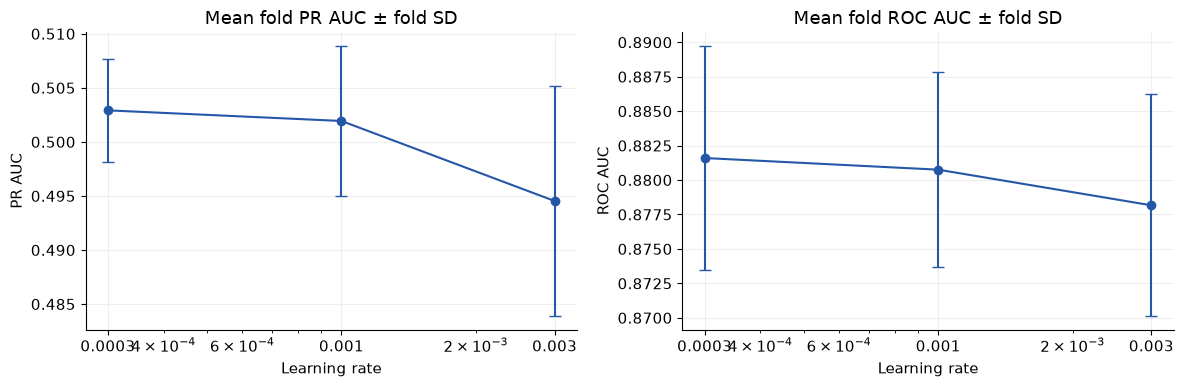

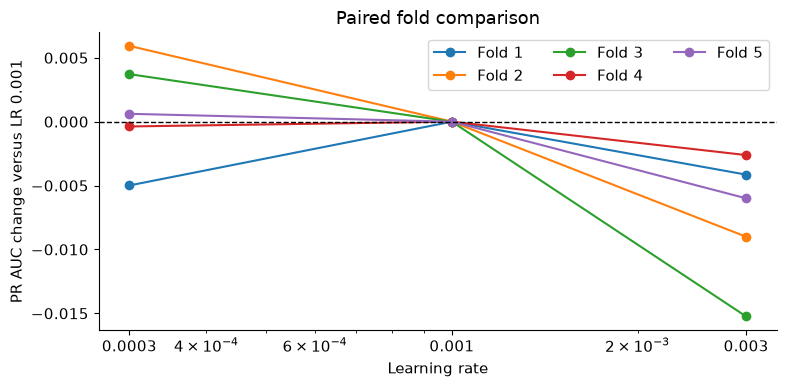

In [16]:
FIG_DIR = RUN_DIR/'figures'; FIG_DIR.mkdir(exist_ok=True)
ordered = leaderboard.sort_values('lr')
names = ordered.candidate.tolist()
colors = dict(zip(names, plt.get_cmap('tab10').colors))
def finish_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR/f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()

fig, axes = plt.subplots(1,2,figsize=(12,4))
for ax, metric in zip(axes,['PR_AUC','ROC_AUC']):
    ax.errorbar(ordered.lr, ordered['mean_'+metric], yerr=ordered['sd_'+metric], fmt='o-', capsize=4, color='#2457A7')
    ax.set(xlabel='Learning rate', ylabel=metric.replace('_',' '), title='Mean fold '+metric.replace('_',' ')+' ± fold SD')
    ax.set_xscale('log'); ax.set_xticks(ordered.lr, [f'{x:g}' for x in ordered.lr]); ax.grid(alpha=.2)
finish_figure(fig,'01_mean_fold_metrics')

reference = fold_metrics.loc[fold_metrics.lr.eq(REFERENCE_LR),['fold','PR_AUC_trapezoidal']].rename(columns={'PR_AUC_trapezoidal':'reference'})
paired = fold_metrics.merge(reference,on='fold',validate='many_to_one')
paired['delta_PR_AUC'] = paired.PR_AUC_trapezoidal-paired.reference
paired.to_csv(RUN_DIR/'paired_fold_deltas.csv',index=False)
fig, ax = plt.subplots(figsize=(8,4))
for fold, block in paired.groupby('fold'):
    block=block.sort_values('lr')
    ax.plot(block.lr,block.delta_PR_AUC,marker='o',label=f'Fold {fold}')
ax.set_xscale('log'); ax.set_xticks(ordered.lr, [f'{x:g}' for x in ordered.lr])
ax.axhline(0,color='black',ls='--',lw=1)
ax.set(xlabel='Learning rate',ylabel=f'PR AUC change versus LR {REFERENCE_LR:g}',title='Paired fold comparison'); ax.legend(ncol=3)
finish_figure(fig,'02_paired_deltas')

## 10. Per-dataset PR AUC and ROC AUC
Compare candidates within each dataset. PR AUC depends on positive prevalence: dataset 2’s high positive fraction makes its PR AUC unsuitable for direct comparison with dataset 0’s. Counts and prevalence are in the table above.

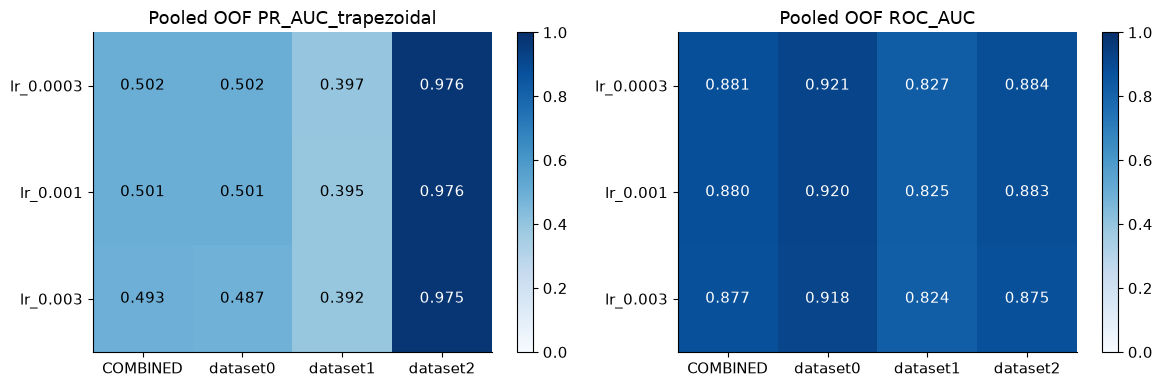

In [17]:
fig, axes = plt.subplots(1,2,figsize=(12,4))
for ax, metric in zip(axes,['PR_AUC_trapezoidal','ROC_AUC']):
    matrix=dataset_metrics.pivot(index='candidate',columns='dataset_id',values=metric).reindex(names)
    im=ax.imshow(matrix.to_numpy(),vmin=0,vmax=1,cmap='Blues',aspect='auto')
    ax.set_xticks(range(len(matrix.columns)),matrix.columns)
    ax.set_yticks(range(len(names)),names); ax.set_title('Pooled OOF '+metric)
    for i in range(len(matrix)):
        for j in range(len(matrix.columns)):
            v=matrix.iloc[i,j]
            ax.text(j,i,f'{v:.3f}' if np.isfinite(v) else 'N/A',ha='center',va='center',color='white' if v>.65 else 'black')
    fig.colorbar(im,ax=ax)
finish_figure(fig,'03_dataset_metrics')

## 11. OOF PR and ROC curves
Each panel uses identical rows across candidates. The PR dashed line is positive prevalence; the ROC dashed line is chance ranking. These curves combine predictions from five fitted models per candidate.

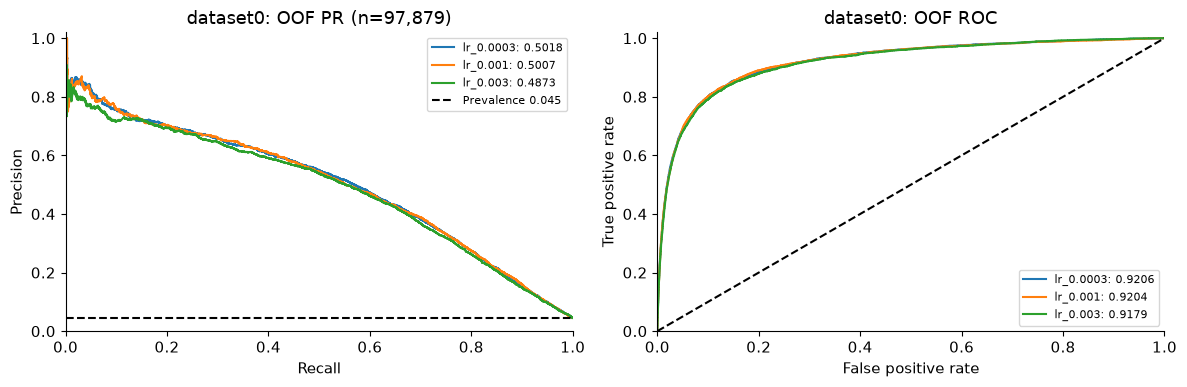

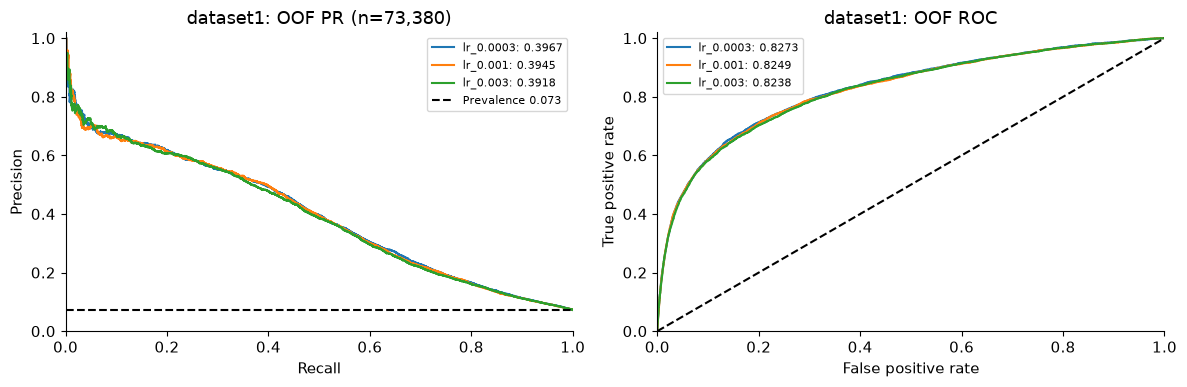

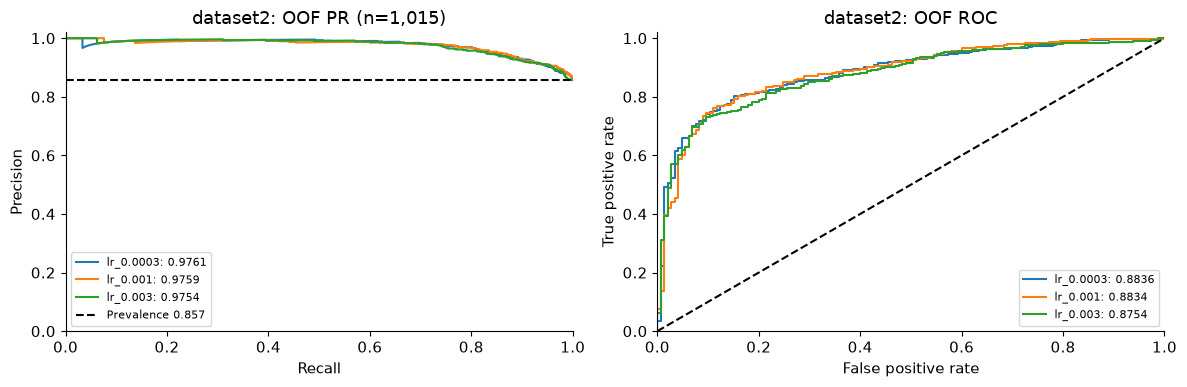

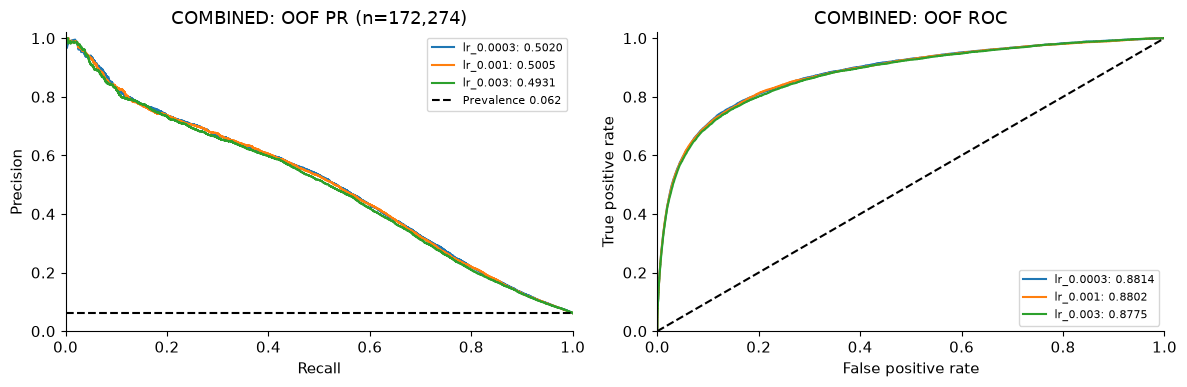

In [18]:
oof = {name: pd.read_csv(RUN_DIR/name/'oof_predictions.csv.gz', dtype={'transcript_id':str}) for name in names}
reference_frame=oof[names[0]]
for frame in oof.values():
    assert frame[['dataset_id']+KEY+['label','validation_fold']].equals(reference_frame[['dataset_id']+KEY+['label','validation_fold']])
for dataset in [*reference_frame.dataset_id.unique(),'COMBINED']:
    mask = np.ones(len(reference_frame),dtype=bool) if dataset=='COMBINED' else reference_frame.dataset_id.eq(dataset).to_numpy()
    y=reference_frame.loc[mask,'label'].to_numpy()
    if len(np.unique(y))<2:
        print(dataset,': skipped curves (fewer than two classes)'); continue
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for name in names:
        p=oof[name].loc[mask,'score'].to_numpy()
        precision,recall,_=precision_recall_curve(y,p)
        fpr,tpr,_=roc_curve(y,p)
        axes[0].plot(recall,precision,color=colors[name],label=f'{name}: {auc(recall,precision):.4f}')
        axes[1].plot(fpr,tpr,color=colors[name],label=f'{name}: {roc_auc_score(y,p):.4f}')
    axes[0].axhline(y.mean(),color='black',ls='--',label=f'Prevalence {y.mean():.3f}')
    axes[1].plot([0,1],[0,1],'k--')
    axes[0].set(xlabel='Recall',ylabel='Precision',title=f'{dataset}: OOF PR (n={len(y):,})')
    axes[1].set(xlabel='False positive rate',ylabel='True positive rate',title=f'{dataset}: OOF ROC')
    for ax in axes: ax.set_xlim(0,1); ax.set_ylim(0,1.02); ax.legend(fontsize=8)
    finish_figure(fig,f'04_curves_{dataset}')

## 12. Epoch diagnostics
Each fold stops independently. The first chart averages **only the folds still running** at each epoch, so its composition changes after the first stop. The second chart shows every fold separately, marks its selected epoch, and reports how many folds contribute. Use these individual curves to assess whether folds were still improving at the maximum. No test scores are used.


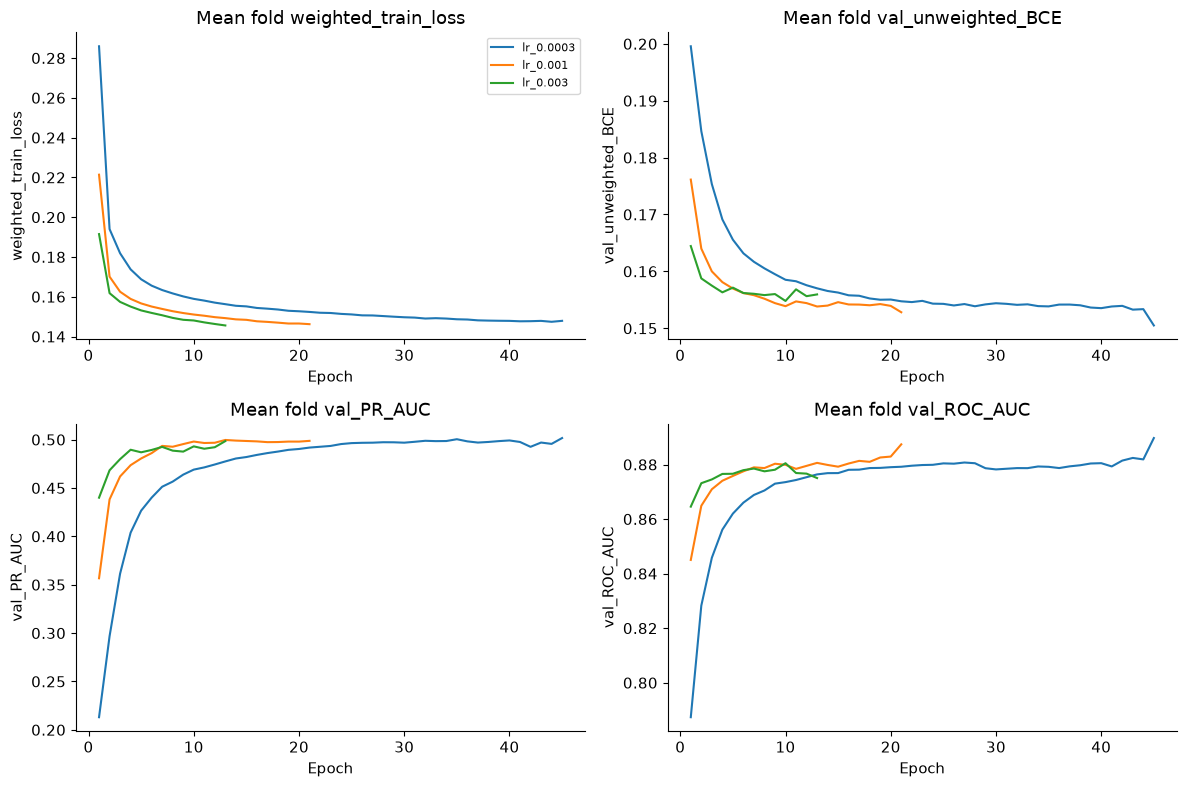

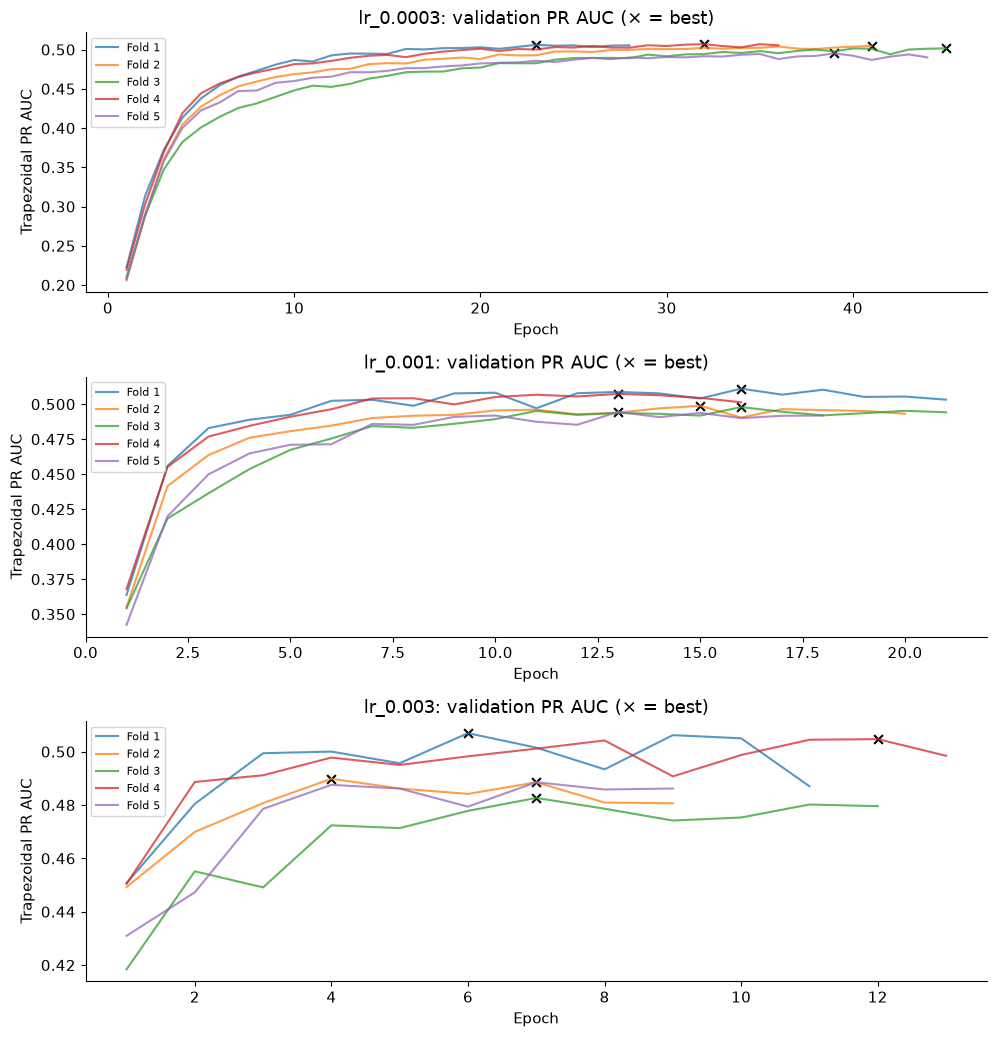

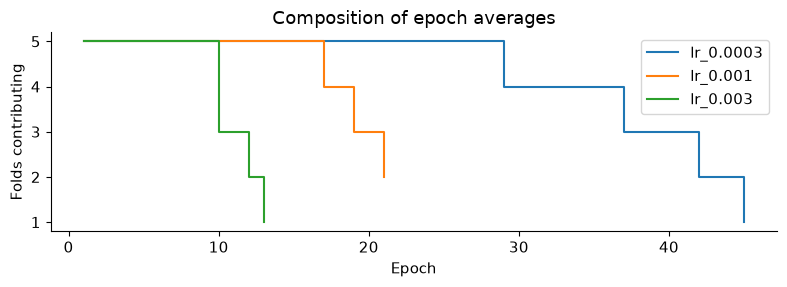

In [19]:
histories=[]
for name in names:
    for path in sorted((RUN_DIR/name).glob('fold_*_history.csv')):
        histories.append(pd.read_csv(path).assign(candidate=name,fold=int(path.name.split('_')[1])))
history=pd.concat(histories,ignore_index=True)
history.to_csv(RUN_DIR/'all_epoch_history.csv',index=False)
fig,axes=plt.subplots(2,2,figsize=(12,8))
for name in names:
    h=history.loc[history.candidate.eq(name)].groupby('epoch').mean(numeric_only=True)
    for ax,metric in zip(axes.flat,['weighted_train_loss','val_unweighted_BCE','val_PR_AUC','val_ROC_AUC']):
        ax.plot(h.index,h[metric],label=name,color=colors[name]); ax.set(xlabel='Epoch',ylabel=metric,title='Mean fold '+metric)
axes.flat[0].legend(fontsize=8)
finish_figure(fig,'05_epoch_diagnostics')
fig,axes=plt.subplots(len(names),1,figsize=(10,3.5*len(names)),squeeze=False)
for ax,name in zip(axes.flat,names):
    for fold,h in history.loc[history.candidate.eq(name)].groupby('fold'):
        ax.plot(h.epoch,h.val_PR_AUC,alpha=.75,label=f'Fold {fold}')
        best=h.loc[h.val_PR_AUC.idxmax()]
        ax.scatter(best.epoch,best.val_PR_AUC,s=40,marker='x',color='black')
    ax.set(title=f'{name}: validation PR AUC (× = best)',xlabel='Epoch',ylabel='Trapezoidal PR AUC')
    ax.legend(fontsize=8)
finish_figure(fig,'07_individual_fold_epochs')
counts=history.groupby(['candidate','epoch']).size().rename('active_folds').reset_index()
counts.to_csv(RUN_DIR/'epoch_active_fold_counts.csv',index=False)
fig,ax=plt.subplots(figsize=(8,3))
for name,h in counts.groupby('candidate'):
    ax.step(h.epoch,h.active_folds,where='post',label=name,color=colors[name])
ax.set(xlabel='Epoch',ylabel='Folds contributing',title='Composition of epoch averages',yticks=range(1,N_FOLDS+1))
ax.legend(); finish_figure(fig,'08_active_fold_counts')


## 13. Compute cost and next steps
Compare recorded CV runtime across learning rates. All models have the same parameter count. Runtime depends on hardware, concurrent workloads and epochs actually run. Weighted training loss and unweighted validation BCE have different weighting and should not be compared as identical objectives.

Next, tune **classification-head dropout** (0.0, 0.2, 0.4) with this round's selected learning rate and all other settings fixed. Later tune weight decay, batch size, then a few learning-rate/batch-size combinations. This notebook launches only learning-rate tuning.

`selected_config.json` and `next_round_handoff.json` carry the winner forward. The rounded median best epoch is a provisional final-fit duration; recompute after remaining tuning. No all-TRAIN refit or TEST predictions run here.

For reload, set `RUN_TRAINING=False` and `EXISTING_RUN_DIR` to this completed Round 4 run. For resume, use `RUN_TRAINING=True`. Keep upstream Round 1/2/3 output directories available. Only load trusted model/scaler files.


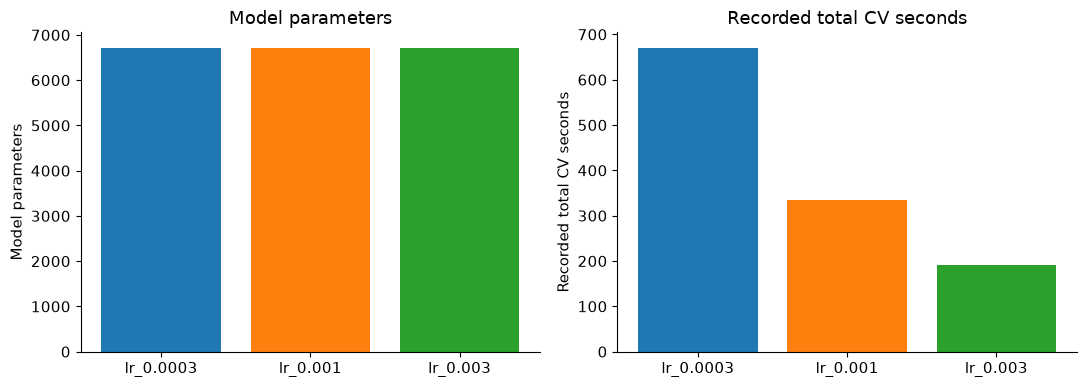

Next stage: classification-head dropout tuning; TEST remains untouched.


In [20]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,metric,label in zip(axes,['parameters','seconds'],['Model parameters','Recorded total CV seconds']):
    ax.bar(ordered.candidate,ordered[metric],color=[colors[n] for n in names])
    ax.set(ylabel=label,title=label); ax.set_ylim(bottom=0)
finish_figure(fig,'06_compute_cost')
print('Next stage: classification-head dropout tuning; TEST remains untouched.')